# Checkpoint 3 — Clustering aplicado à energia

**Atividade prática em Python | K-Means, Elbow e Silhouette Score**

**Nome(s) e RM(s):** ARTHUR ARAUJO MASSARIOLI e RM: 573308

**Turma:** 1CCPK

## Situação-problema

Uma equipe de gestão de energia quer conhecer os diferentes perfis de uso de suas unidades consumidoras para planejar ações de acompanhamento e uso consciente de energia. Cada registro reúne informações de uma unidade no mesmo mês de referência.

Seu desafio é identificar grupos de unidades com comportamentos semelhantes, justificar a quantidade de clusters e propor uma ação coerente para cada perfil encontrado.

Não há uma coluna com a classificação correta. A qualidade da análise depende da preparação dos dados, das evidências apresentadas e da interpretação dos agrupamentos.

## O que desenvolver

1. Explorar a base e selecionar as variáveis.
2. Padronizar as variáveis numéricas.
3. Aplicar K-Means e investigar diferentes valores de **k**.
4. Construir os gráficos de **Elbow** e **Silhouette Score**.
5. Justificar o k escolhido, visualizar os grupos e interpretar seus perfis.
6. Apresentar conclusões e limitações da análise.

As células de importação e leitura estão prontas. Complete as demais células de código e os espaços de resposta. Execute o notebook na ordem, mantendo os resultados visíveis.


## 1. Conheça a base

Esta base contém **120 unidades consumidoras fictícias**. Os dados foram gerados previamente com NumPy e semente 303, para fins didáticos, e estão incorporados neste notebook como texto CSV. **Não foram coletados de medidores, empresas ou bases públicas.** A célula de leitura apenas carrega os dados; não gera novos valores.

| Coluna | Significado | Unidade / uso |
| --- | --- | --- |
| `id_unidade` | Identificador da unidade consumidora | Identificação; excluir do modelo |
| `consumo_mensal_kwh` | Energia total consumida no mês | kWh |
| `demanda_maxima_kw` | Maior demanda de potência média registrada em uma janela de 15 minutos no mês | kW |
| `consumo_noturno_pct` | Parcela da energia mensal consumida entre 18h e 6h | % entre 0 e 100 |

Energia, em kWh, representa o consumo acumulado; potência, em kW, representa a taxa de uso de energia. O percentual noturno descreve o horário de consumo. Nenhuma dessas variáveis, isoladamente, permite afirmar que uma unidade desperdiça energia ou que paga uma tarifa maior.

Não substitua a base. Use as três variáveis numéricas no agrupamento principal.


In [1]:
# Bibliotecas utilizadas na atividade.
from io import StringIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

plt.rcParams['figure.figsize'] = (9, 5)


In [2]:
# Base simulada incorporada ao notebook: não é necessário baixar um CSV.
DADOS_CSV = """
id_unidade,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
UC001,791.43,7.28,23.95
UC002,1349.44,6.65,72.17
UC003,1355.67,6.5,76.47
UC004,209.34,0.5,67.76
UC005,1675.8,5.99,78.53
UC006,259.28,3.13,59.3
UC007,180.39,3.38,61.37
UC008,1705.73,8.78,76.28
UC009,1421.17,6.34,66.16
UC010,769.67,8.28,13.51
UC011,1003.9,6.81,24.07
UC012,1136.69,5.5,39.81
UC013,1237.83,5.41,28.87
UC014,1358.74,4.78,26.72
UC015,696.34,7.57,32.59
UC016,330.75,1.83,64.99
UC017,1448.43,6.91,69.18
UC018,1559.32,4.87,75.15
UC019,208.86,2.98,79.31
UC020,1340.84,5.18,51.64
UC021,1666.35,6.22,54.65
UC022,684.26,7.29,21.61
UC023,1858.04,6.28,57.13
UC024,1548.18,5.13,76.59
UC025,1286.54,7.4,70.44
UC026,671.62,6.18,27.59
UC027,286.11,1.74,71.6
UC028,306.77,2.73,70.48
UC029,191.95,2.71,46.75
UC030,160.72,3.07,46.56
UC031,1914.05,6.29,67.69
UC032,639.82,5.55,22.34
UC033,1343.78,5.82,71.13
UC034,199.73,2.95,66.44
UC035,1466.32,6.83,59.17
UC036,166.38,2.19,58.04
UC037,754.59,11.69,30.64
UC038,256.47,1.57,61.37
UC039,1440.36,5.28,72.3
UC040,1112.84,10.02,30.37
UC041,1325.72,7.23,65.96
UC042,1244.96,7.05,61.76
UC043,1580.58,8.86,61.86
UC044,288.92,3.5,48.41
UC045,1413.1,5.86,73.32
UC046,1243.79,9.36,74.18
UC047,1018.37,8.09,16.74
UC048,889.65,7.82,20.83
UC049,293.69,2.78,49.17
UC050,239.89,2.61,50.72
UC051,1149.27,4.41,69.7
UC052,903.31,6.04,47.47
UC053,1447.32,7.0,60.31
UC054,324.49,3.43,57.92
UC055,975.35,7.83,24.91
UC056,253.75,3.19,47.61
UC057,185.26,2.79,60.37
UC058,275.33,2.06,76.62
UC059,1173.41,8.29,27.67
UC060,336.68,1.44,61.73
UC061,1472.11,5.42,56.01
UC062,1420.31,5.76,69.66
UC063,1066.74,7.03,8.35
UC064,1206.7,4.49,65.74
UC065,301.5,2.46,62.06
UC066,471.96,4.72,22.2
UC067,793.83,6.47,39.74
UC068,814.11,8.18,20.03
UC069,1083.2,6.04,24.84
UC070,835.44,8.55,26.43
UC071,191.85,1.84,50.14
UC072,541.54,5.65,23.23
UC073,266.76,2.93,58.84
UC074,234.77,3.06,73.52
UC075,1070.5,6.15,25.14
UC076,1270.27,3.3,71.85
UC077,212.02,2.76,59.79
UC078,1426.91,6.37,54.31
UC079,226.26,2.13,63.17
UC080,130.01,2.74,56.49
UC081,695.66,3.84,37.71
UC082,1599.27,5.34,49.98
UC083,1357.57,3.68,74.87
UC084,1373.33,6.77,90.34
UC085,504.17,6.68,39.48
UC086,328.86,3.42,65.21
UC087,1134.59,7.04,73.45
UC088,194.57,2.38,72.45
UC089,945.97,5.09,17.76
UC090,1441.73,6.74,44.47
UC091,1524.46,6.97,78.07
UC092,714.84,8.2,13.75
UC093,1379.84,6.47,64.98
UC094,1108.56,5.36,64.45
UC095,210.07,2.21,54.13
UC096,1174.74,5.89,18.89
UC097,644.55,6.99,27.88
UC098,208.74,2.93,67.23
UC099,1873.16,4.36,64.23
UC100,1138.21,7.79,24.51
UC101,270.96,2.2,62.31
UC102,784.72,9.76,32.76
UC103,1237.88,4.97,79.03
UC104,841.88,7.37,15.06
UC105,1362.73,3.61,63.05
UC106,666.95,7.15,17.58
UC107,1136.73,2.2,26.42
UC108,222.53,2.76,69.93
UC109,206.28,2.32,43.43
UC110,197.03,3.69,59.72
UC111,294.74,2.25,70.32
UC112,319.74,2.93,55.82
UC113,379.07,2.13,61.4
UC114,305.26,3.2,52.56
UC115,868.46,7.37,24.69
UC116,147.71,2.36,67.72
UC117,606.83,6.35,21.84
UC118,1382.92,9.14,68.61
UC119,967.14,7.18,29.84
UC120,874.2,5.62,21.92
"""
df = pd.read_csv(StringIO(DADOS_CSV))
print(df.head().to_string(index=False))
print(f"Unidades consumidoras: {len(df)}")


id_unidade  consumo_mensal_kwh  demanda_maxima_kw  consumo_noturno_pct
     UC001              791.43               7.28                23.95
     UC002             1349.44               6.65                72.17
     UC003             1355.67               6.50                76.47
     UC004              209.34               0.50                67.76
     UC005             1675.80               5.99                78.53
Unidades consumidoras: 120


## 2. Exploração dos dados — 1,0 ponto

Apresente o tamanho da base, os tipos das colunas, a quantidade de valores ausentes e as estatísticas descritivas das três variáveis numéricas. Verifique se os identificadores se repetem.

Responda: quais variáveis apresentam maior amplitude? Por que usar apenas o consumo mensal poderia esconder diferenças de comportamento?


In [9]:
# Exploração inicial da base
features_exploracao = ['consumo_mensal_kwh', 'demanda_maxima_kw', 'consumo_noturno_pct']
print('Dimensões da base:', df.shape)
print('Tipos das colunas:')
print(df.dtypes)
print()
print('Valores ausentes por coluna:')
print(df.isna().sum())
print('Estatísticas descritivas:')
display(df[features_exploracao].describe().T.round(2))
print()
print('Identificadores duplicados:', df['id_unidade'].duplicated().sum())
print('Quantidade de identificadores únicos:', df['id_unidade'].nunique())

Dimensões da base: (120, 4)
Tipos das colunas:
id_unidade              object
consumo_mensal_kwh     float64
demanda_maxima_kw      float64
consumo_noturno_pct    float64
dtype: object

Valores ausentes por coluna:
id_unidade             0
consumo_mensal_kwh     0
demanda_maxima_kw      0
consumo_noturno_pct    0
dtype: int64
Estatísticas descritivas:


,count,mean,std,min,25%,50%,75%,max
consumo_mensal_kwh,120.0,851.84,516.24,130.01,294.48,855.17,1341.57,1914.05
demanda_maxima_kw,120.0,5.20,2.30,0.50,2.97,5.46,6.98,11.69
consumo_noturno_pct,120.0,51.23,20.39,8.35,29.60,57.98,67.73,90.34



Identificadores duplicados: 0
Quantidade de identificadores únicos: 120


**Resposta e observações:**

A base possui **120 linhas e 4 colunas**: um identificador (`id_unidade`) e três variáveis numéricas. As variáveis numéricas são do tipo `float64` e o identificador é `object`. Não há valores ausentes e os 120 identificadores são únicos, sem repetição.

As amplitudes observadas são: consumo mensal de **1.784,04 kWh** (de 130,01 a 1.914,05), demanda máxima de **11,19 kW** (de 0,50 a 11,69) e consumo noturno de **81,99 pontos percentuais** (de 8,35% a 90,34%). Em suas unidades originais, não é adequado comparar diretamente a magnitude dessas amplitudes porque as unidades são diferentes.

Usar somente o consumo mensal esconderia diferenças entre unidades que consomem quantidades parecidas, mas apresentam demandas máximas ou distribuição horária distintas. As três variáveis descrevem dimensões complementares do perfil de uso.

## 3. Preparação e padronização — 1,5 ponto

Crie `X` com as três variáveis numéricas, preservando `df` nas unidades originais. Use `StandardScaler` para criar `X_padronizado`.

Como as escalas diferem, uma variável pode dominar as distâncias. O `StandardScaler` centraliza e divide pelo desvio padrão; ele não converte os dados para o intervalo de 0 a 1. Explique por que essa transformação é pertinente neste problema.

**Cuidado:** não inclua `id_unidade` nem os rótulos dos clusters entre as variáveis do modelo. Use a mesma matriz padronizada para ajustar e avaliar os agrupamentos.


In [12]:
# Seleção das variáveis explicativas (sem identificador)
X = df[['consumo_mensal_kwh', 'demanda_maxima_kw', 'consumo_noturno_pct']].copy()

# Padronização: média próxima de zero e desvio padrão próximo de um
scaler = StandardScaler()
X_padronizado = scaler.fit_transform(X)

print('Formato de X:', X.shape)
print('Formato de X_padronizado:', X_padronizado.shape)
print('Médias após padronização:', np.round(X_padronizado.mean(axis=0), 4))
print('Desvios padrão após padronização:', np.round(X_padronizado.std(axis=0), 4))
display(pd.DataFrame(X_padronizado, columns=X.columns).head())

Formato de X: (120, 3)
Formato de X_padronizado: (120, 3)
Médias após padronização: [-0. -0. -0.]
Desvios padrão após padronização: [1. 1. 1.]


,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
0,-0.117509,0.907433,-1.343110
1,0.967933,0.632574,1.031131
2,0.980052,0.567132,1.242853
3,-1.249792,-2.050567,0.813993
4,1.602769,0.344627,1.344283


**Justificativa da padronização:**

As variáveis estão em escalas e unidades diferentes: kWh, kW e percentual. Como o K-Means utiliza distâncias para formar os grupos, uma variável com valores numericamente maiores poderia influenciar mais o cálculo apenas por sua escala. O `StandardScaler` transforma cada variável para uma escala comparável, subtraindo a média e dividindo pelo desvio padrão. Assim, consumo, demanda e participação noturna podem contribuir para as distâncias sem que seja necessário alterar os valores originais de `df`, que serão usados depois para interpretar os grupos.

## Apoio: centroides, inércia e distorções

O **centroide** é a média das coordenadas dos pontos de um grupo. O K-Means procura grupos compactos ao reduzir a soma das distâncias quadráticas dos pontos aos centroides atribuídos.

A **inércia**, disponível em `modelo.inertia_`, é essa soma:

$$J = \sum_{i=1}^{n}\left\|x_i-\mu_{c(i)}\right\|^2$$

Por exemplo, consumos de 100, 120 e 140 kWh formam um grupo com centroide de 120 kWh. Usando apenas essa variável, sem padronização:

$$J=(100-120)^2+(120-120)^2+(140-120)^2=800\;\mathrm{kWh}^2$$

Neste notebook, **distorções** será o nome da lista que armazena os valores de `inertia_`; aqui, os dois termos se referem à mesma medida. Em outros materiais, distorção pode designar uma média; confira a definição usada.

Com variáveis padronizadas, a inércia é calculada nesse espaço transformado. Ela não representa kWh consumidos. Compare valores obtidos com as mesmas variáveis e a mesma preparação.


## 4. Método Elbow — 1,5 ponto

Ajuste um K-Means para cada **k de 1 a 8** sobre `X_padronizado`. Use `random_state=42` e `n_init=10` em todos os ajustes para tornar a comparação reproduzível no mesmo ambiente. Armazene `inertia_` na lista `distorcoes` e construa um gráfico com k no eixo horizontal e inércia no vertical.

**Como ler:** aumentar k tende a reduzir a inércia. Procure a região em que as quedas passam a ser menores: o possível cotovelo. Isso indica ganho adicional reduzido ao criar mais grupos, sem determinar sozinho a melhor solução.

Exemplo ilustrativo, sem relação com a base: inércias 900, 460, 210, 190 e 176 para k de 1 a 5 sugerem investigar k = 3. A queda de 2 para 3 é grande; as seguintes são menores. Algumas bases não apresentam cotovelo nítido.

Indique a região candidata observada no seu gráfico e explique a mudança das quedas de inércia.


,k,inercia
0,1,360.000
1,2,184.696
2,3,74.253
3,4,61.103
4,5,52.062
5,6,46.362
6,7,40.896
7,8,37.246


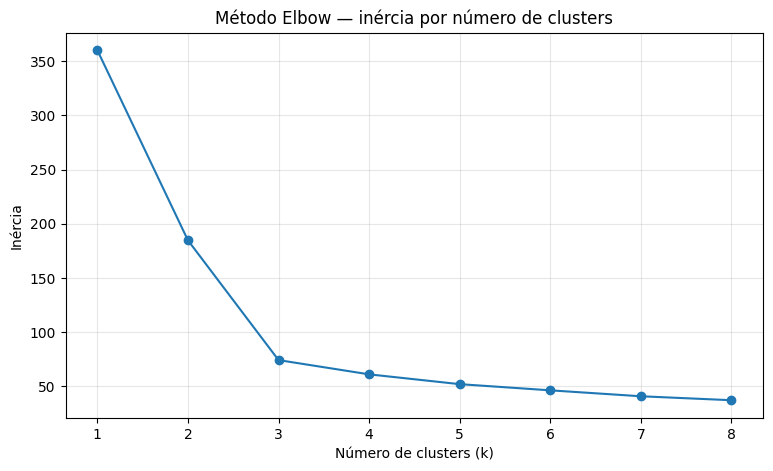

In [13]:
# Método Elbow: testar k de 1 a 8 com parâmetros fixos
valores_k = range(1, 9)
distorcoes = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(X_padronizado)
    distorcoes.append(modelo.inertia_)

tabela_elbow = pd.DataFrame({'k': list(valores_k), 'inercia': distorcoes})
display(tabela_elbow.round(3))

plt.figure()
plt.plot(list(valores_k), distorcoes, marker='o')
plt.title('Método Elbow — inércia por número de clusters')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inércia')
plt.xticks(list(valores_k))
plt.grid(True, alpha=0.3)
plt.show()

**Leitura do Elbow:**

A inércia diminui de **360,00 (k=1)** para **184,70 (k=2)** e cai novamente de forma acentuada para **74,25 (k=3)**. A partir daí, as reduções ficam menores: por exemplo, de k=3 para k=4 a inércia cai para **61,10**, uma redução de aproximadamente 13,15, bem menor que a queda de 110,44 entre k=2 e k=3. O gráfico sugere uma região de cotovelo em **k=3**, embora o Elbow seja uma evidência visual e não determine sozinho a solução.

## Apoio: Silhouette Score

Para cada ponto, compara-se a distância média aos demais pontos do seu grupo, $a$, com a menor distância média a outro grupo, $b$:

$$s=\frac{b-a}{\max(a,b)}$$

O **Silhouette Score** é a média dos valores individuais. Para um grupo com um único ponto, adota-se score individual zero.

- Próximo de **1**: grupos compactos e separados segundo as distâncias utilizadas.
- Próximo de **0**: sobreposição ou pontos perto das fronteiras.
- **Negativo**: pontos, em média, mais próximos de outro grupo.

Se $a=2$ e $b=8$, o valor individual é 0,75. Isso **não significa 75% de acertos**: não existe comparação com classes corretas. Não há um limiar universal que valide qualquer agrupamento.

O cálculo exige entre 2 e $n-1$ grupos distintos. Por isso, k = 1 participa do Elbow, mas não da comparação de Silhouette Score. A média pode esconder situações diferentes dentro de cada grupo.


## 5. Comparação por Silhouette Score — 1,5 ponto

Teste **k de 2 a 8**, mantendo `random_state=42` e `n_init=10`. Para cada k, obtenha os rótulos e calcule `silhouette_score(X_padronizado, rotulos)`.

Apresente uma tabela com k e score, além de um gráfico com esses valores. Identifique o maior score do intervalo testado e compare-o com a indicação do Elbow. Se houver divergência, explique-a e justifique sua decisão considerando também a interpretação dos perfis.

Não adicione a coluna de clusters a `X_padronizado` para calcular a métrica. Isso alteraria as distâncias que você pretende avaliar.


,k,silhouette_score
0,2,0.4835
1,3,0.6031
2,4,0.5190
3,5,0.4282
4,6,0.4343
5,7,0.3240
6,8,0.3106


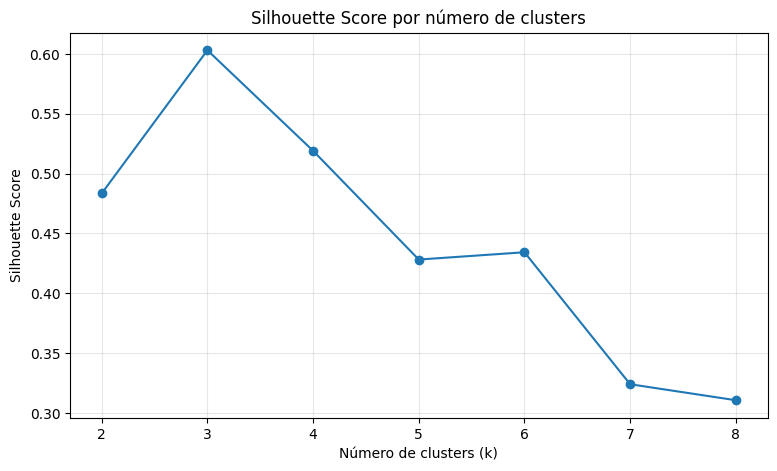

Maior score: k=3, score=0.6031


In [14]:
# Silhouette Score para k de 2 a 8
resultados_silhouette = []

for k in range(2, 9):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    rotulos = modelo.fit_predict(X_padronizado)
    score = silhouette_score(X_padronizado, rotulos)
    resultados_silhouette.append({'k': k, 'silhouette_score': score})

tabela_silhouette = pd.DataFrame(resultados_silhouette)
display(tabela_silhouette.round(4))

plt.figure()
plt.plot(tabela_silhouette['k'], tabela_silhouette['silhouette_score'], marker='o')
plt.title('Silhouette Score por número de clusters')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 9))
plt.grid(True, alpha=0.3)
plt.show()

melhor_linha = tabela_silhouette.loc[tabela_silhouette['silhouette_score'].idxmax()]
print(f"Maior score: k={int(melhor_linha['k'])}, score={melhor_linha['silhouette_score']:.4f}")

**Comparação das evidências:**

O maior Silhouette Score no intervalo testado ocorre em **k=3**, com **0,6031**. Para comparação, k=2 apresenta 0,4835 e k=4 apresenta 0,5190; os valores diminuem nos demais k testados. Isso indica que, segundo as distâncias padronizadas, a solução com três grupos apresenta melhor combinação média de coesão interna e separação entre grupos entre as alternativas avaliadas.

O resultado converge com o Elbow, cujo cotovelo também aparece em k=3. Como as duas evidências apontam para o mesmo valor, k=3 é uma escolha justificável. O score não representa percentual de acertos: não existem rótulos verdadeiros nesta atividade.

## 6. Escolha de k e agrupamento final — 1,0 ponto

Defina `k_escolhido`, ajuste o modelo final sobre `X_padronizado` e crie `df_resultados` como uma cópia de `df`, acrescentando a coluna `cluster`.

Apresente a quantidade de unidades por grupo e o Silhouette Score final. Justifique k com base nas etapas anteriores. Os números dos clusters são apenas identificadores: cluster 2 não é necessariamente maior ou melhor que cluster 0.


In [16]:
# Modelo final com k escolhido a partir das evidências anteriores
k_escolhido = 3
modelo_final = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)
rotulos_finais = modelo_final.fit_predict(X_padronizado)

df_resultados = df.copy()
df_resultados['cluster'] = rotulos_finais

score_final = silhouette_score(X_padronizado, rotulos_finais)
print('Quantidade de unidades por cluster:')
display(df_resultados['cluster'].value_counts().sort_index().rename('quantidade').to_frame())
print(f'Silhouette Score final: {score_final:.4f}')
display(df_resultados.head())

Quantidade de unidades por cluster:


,quantidade
cluster,
0,40
1,40
2,40


Silhouette Score final: 0.6031


,id_unidade,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct,cluster
0,UC001,791.43,7.28,23.95,0
1,UC002,1349.44,6.65,72.17,2
2,UC003,1355.67,6.50,76.47,2
3,UC004,209.34,0.50,67.76,1
4,UC005,1675.80,5.99,78.53,2


**k escolhido e justificativa:**

Foi escolhido **k=3** porque o gráfico Elbow mostra uma redução muito expressiva da inércia até três grupos e ganhos menores depois desse ponto. Além disso, k=3 obteve o maior Silhouette Score entre k=2 e k=8 (**0,6031**). O modelo final foi ajustado com `random_state=42` e `n_init=10`, e o score final foi **0,6031**. Cada cluster contém 40 unidades nesta execução. Os números 0, 1 e 2 são apenas rótulos atribuídos pelo algoritmo, sem ordem de qualidade.

## 7. Visualização e interpretação — 2,0 pontos

Construa dois gráficos de dispersão, usando as cores para identificar os clusters:

1. Consumo mensal × demanda máxima.
2. Consumo mensal × percentual de consumo noturno.

Use valores nas unidades originais, títulos, unidades nos eixos e uma legenda que identifique os grupos. Os gráficos mostram projeções em duas dimensões; o modelo utilizou três variáveis.

Crie uma tabela com a quantidade de unidades e as médias das três variáveis por cluster, nas unidades originais. Descreva cada perfil usando esses números e proponha uma ação de gestão de energia para cada um. Diferencie o que os dados mostram do que ainda precisaria ser investigado.

Consumo alto não prova desperdício. Uma recomendação sobre tarifa ou geração solar exigiria dados adicionais de contrato, horários, local e viabilidade.


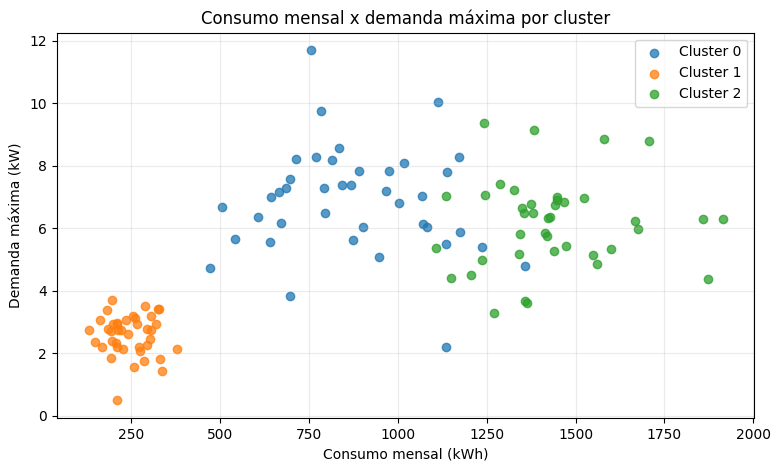

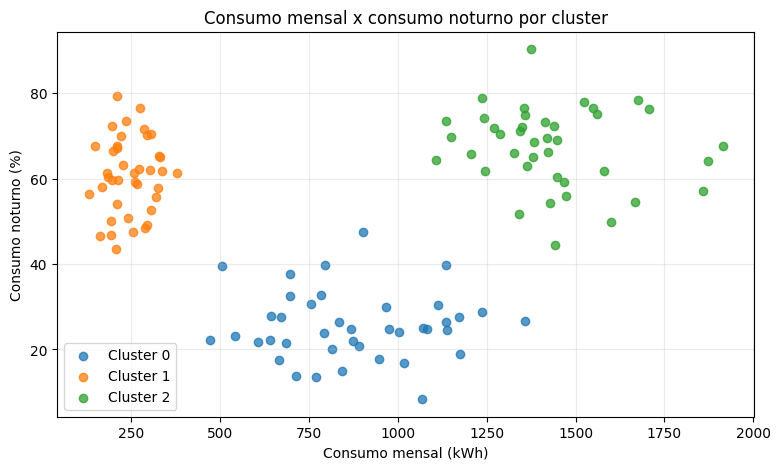

In [17]:
# Gráfico 1: consumo mensal x demanda máxima
plt.figure()
for cluster_id in sorted(df_resultados['cluster'].unique()):
    parte = df_resultados[df_resultados['cluster'] == cluster_id]
    plt.scatter(parte['consumo_mensal_kwh'], parte['demanda_maxima_kw'],
                label=f'Cluster {cluster_id}', alpha=0.75)
plt.title('Consumo mensal x demanda máxima por cluster')
plt.xlabel('Consumo mensal (kWh)')
plt.ylabel('Demanda máxima (kW)')
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()

# Gráfico 2: consumo mensal x percentual noturno
plt.figure()
for cluster_id in sorted(df_resultados['cluster'].unique()):
    parte = df_resultados[df_resultados['cluster'] == cluster_id]
    plt.scatter(parte['consumo_mensal_kwh'], parte['consumo_noturno_pct'],
                label=f'Cluster {cluster_id}', alpha=0.75)
plt.title('Consumo mensal x consumo noturno por cluster')
plt.xlabel('Consumo mensal (kWh)')
plt.ylabel('Consumo noturno (%)')
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()

In [18]:
# Perfil médio de cada grupo nas unidades originais
tabela_perfis = df_resultados.groupby('cluster').agg(
    quantidade=('id_unidade', 'count'),
    consumo_medio_kwh=('consumo_mensal_kwh', 'mean'),
    demanda_media_kw=('demanda_maxima_kw', 'mean'),
    consumo_noturno_medio_pct=('consumo_noturno_pct', 'mean')
).round(2)

display(tabela_perfis)

,quantidade,consumo_medio_kwh,demanda_media_kw,consumo_noturno_medio_pct
cluster,,,,
0,40,876.50,6.87,25.49
1,40,245.09,2.58,60.82
2,40,1433.93,6.15,67.37


**Interpretação dos perfis e ações propostas:**

| Cluster | Evidências numéricas e perfil | Ação proposta | Informação adicional necessária |
| --- | --- | --- | --- |
| 0 | 40 unidades; consumo médio de **876,50 kWh**, demanda média de **6,87 kW** e consumo noturno médio de **25,49%**. Perfil de consumo intermediário, com maior concentração relativa no período diurno. | Investigar os horários de maior demanda e avaliar oportunidades de deslocar cargas flexíveis para horários de menor utilização, se operacionalmente possível. | Curva de carga horária, tipo de atividade, calendário de operação e contrato tarifário. |
| 1 | 40 unidades; consumo médio de **245,09 kWh**, demanda média de **2,58 kW** e consumo noturno médio de **60,82%**. É o grupo de menor consumo e menor demanda média, com participação noturna relevante. | Acompanhar o padrão noturno e verificar se os equipamentos que operam nesse período são necessários e estão configurados adequadamente. | Identificação dos equipamentos, horários reais de funcionamento e histórico de consumo por hora. |
| 2 | 40 unidades; consumo médio de **1.433,93 kWh**, demanda média de **6,15 kW** e consumo noturno médio de **67,37%**. É o grupo de maior consumo médio, com participação noturna elevada. | Priorizar uma auditoria energética e analisar a programação das cargas noturnas, buscando oportunidades de eficiência sem comprometer a operação. | Curva de carga, potência e eficiência dos equipamentos, ocupação, finalidade da unidade e dados tarifários. |

Os dados mostram diferenças de consumo, demanda e distribuição entre períodos, mas não comprovam desperdício, causa do consumo ou custo tarifário. As ações são hipóteses de investigação, não diagnósticos definitivos.

## 8. Conclusão — 1,0 ponto

**Conclusão:**

O agrupamento ajuda a equipe de gestão porque resume as 120 unidades em três perfis com características semelhantes de consumo mensal, demanda máxima e participação noturna. Isso permite organizar o acompanhamento e definir investigações diferentes para cada grupo, em vez de tratar todas as unidades da mesma maneira.

O menor valor de inércia, isoladamente, não escolhe k porque a inércia tende a diminuir quando se adicionam clusters; com k igual ao número de registros, por exemplo, ela pode chegar a zero. É necessário equilibrar a compactação com a simplicidade e a separação dos grupos. Nesta análise, Elbow e Silhouette apontaram para k=3.

O Silhouette Score não mede acurácia porque a base não possui classes verdadeiras para comparar com os grupos encontrados. Ele avalia a coesão e a separação dos agrupamentos com base nas distâncias. A coluna `cluster` deve ficar fora das variáveis de entrada porque é o resultado produzido pelo próprio modelo; incluí-la no cálculo mudaria artificialmente as distâncias e provocaria vazamento do resultado para a avaliação.

Entre as limitações, a primeira é que a base é **simulada e fictícia**, portanto não representa necessariamente o comportamento de consumidores reais. A segunda é que há apenas três variáveis agregadas por unidade e um mês de referência; não há curva horária, clima, tipo de atividade, ocupação, equipamentos ou tarifa. Além disso, o K-Means favorece grupos relativamente compactos e depende da escolha de k e da escala dos dados.

Para aprimorar a análise, seriam úteis dados reais de medidores em intervalos horários ou de 15 minutos, histórico de vários meses, identificação do tipo de unidade, condições climáticas, calendário de operação, potência e eficiência dos equipamentos e informações contratuais. Com esses dados seria possível verificar se os perfis se mantêm ao longo do tempo e investigar as causas das diferenças observadas.

## Entrega e critérios de avaliação

Entregue o **notebook `.ipynb` preenchido e executado**, contendo identificação, códigos, tabelas, gráficos, justificativas e conclusões. A base está incorporada; não é necessário um arquivo externo para executar a atividade. Prazo e canal de entrega serão definidos pelo professor.

| Critério | Pontos |
| --- | ---: |
| Exploração e compreensão dos dados | 1,0 |
| Seleção das variáveis e padronização justificada | 1,5 |
| Elbow: implementação, gráfico e leitura | 1,5 |
| Silhouette Score: comparação, gráfico e interpretação | 1,5 |
| Modelo final e justificativa de k | 1,0 |
| Visualizações, perfis e ações fundamentadas | 2,0 |
| Conclusões e limitações | 1,0 |
| **Total** | **10,0** |

A avaliação considera a correção do código e a capacidade de explicar as escolhas e interpretar os resultados. Não há pontuação por apenas escolher um k específico sem justificativa.

### Antes de entregar

- Preencha nome(s), RM(s) e turma.
- Reinicie o ambiente e execute as células na ordem.
- Confira se as tabelas e os gráficos permanecem salvos no notebook.
- Verifique se usou as três variáveis e excluiu identificador e rótulos do cálculo das distâncias.
- Substitua os espaços de resposta por suas análises.

### Documentação de apoio

- [K-Means e inércia — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Silhouette Score — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [StandardScaler — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

Atividade inspirada na sequência do notebook de referência fornecido pelo professor, com nova base de energia e cuidados adicionais na seleção e avaliação das variáveis.
